In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/clustering/D8/'

In [2]:
df_cosine = pd.read_csv(main_dir + 'UniqueMappingClustering_cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'UniqueMappingClustering_dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'UniqueMappingClustering_jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
#df_scm = pd.read_csv(main_dir + 'UniqueMappingClustering_scm.csv')
#df_scm['similarity'] = 'scm'

In [3]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard]#, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Clustering with UniqueMappingClustering,2508,0.30,cosine,22.01,64.71,32.85,552,1956,23468,301,cosine,[title],1024,0,1,salted_qgrams,,4
1,Clustering with UniqueMappingClustering,2046,0.50,cosine,26.20,62.84,36.98,536,1510,23452,317,cosine,[title],1024,0,1,salted_qgrams,,4
2,Clustering with UniqueMappingClustering,2323,0.40,cosine,23.63,64.36,34.57,549,1774,23465,304,cosine,[title],1024,0,1,salted_qgrams,,4
3,Clustering with UniqueMappingClustering,2554,0.20,cosine,21.61,64.71,32.40,552,2002,23468,301,cosine,[title],1024,0,1,salted_qgrams,,4
4,Clustering with UniqueMappingClustering,1148,0.70,cosine,37.63,50.64,43.18,432,716,23348,421,cosine,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1819,Clustering with UniqueMappingClustering,1,0.55,jaccard,0.00,0.00,0.00,0,1,22916,853,jaccard,[title],1024,0,32,salted_qgrams,,4
1820,Clustering with UniqueMappingClustering,1,0.65,jaccard,0.00,0.00,0.00,0,1,22916,853,jaccard,[title],1024,0,32,salted_qgrams,,4
1821,Clustering with UniqueMappingClustering,15,0.75,jaccard,20.00,0.35,0.69,3,12,22919,850,jaccard,[title],1024,0,32,salted_qgrams,,4
1822,Clustering with UniqueMappingClustering,56,0.85,jaccard,30.36,1.99,3.74,17,39,22933,836,jaccard,[title],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title]    1824
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    1824
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    1824
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    1824
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    1824
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     57
2     57
3     57
4     57
5     57
6     57
7     57
8     57
9     57
10    57
11    57
12    57
13    57
14    57
15    57
16    57
17    57
18    57
19    57
20    57
21    57
22    57
23    57
24    57
25    57
26    57
27    57
28    57
29    57
30    57
31    57
32    57
Name: count, dtype: int64

In [10]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
4,Clustering with UniqueMappingClustering,1148,0.70,cosine,37.63,50.64,43.18,432,716,23348,421,cosine,[title],1024,0,1,salted_qgrams,,4
608,Clustering with UniqueMappingClustering,1079,0.70,dice,38.09,48.18,42.55,411,668,23327,442,dice,[title],1024,0,1,salted_qgrams,,4
1509,Clustering with UniqueMappingClustering,1034,0.55,jaccard,38.78,47.01,42.50,401,633,23317,452,jaccard,[title],1024,0,1,salted_qgrams,,4
13,Clustering with UniqueMappingClustering,1172,0.70,cosine,37.46,51.47,43.36,439,733,23355,414,cosine,[title],1024,0,2,salted_qgrams,,4
620,Clustering with UniqueMappingClustering,1110,0.70,dice,37.39,48.65,42.28,415,695,23331,438,dice,[title],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,Clustering with UniqueMappingClustering,712,0.90,dice,37.22,31.07,33.87,265,447,23181,588,dice,[title],1024,0,31,salted_qgrams,,4
1493,Clustering with UniqueMappingClustering,826,0.80,jaccard,36.92,35.76,36.33,305,521,23221,548,jaccard,[title],1024,0,31,salted_qgrams,,4
287,Clustering with UniqueMappingClustering,772,0.90,cosine,36.14,32.71,34.34,279,493,23195,574,cosine,[title],1024,0,32,salted_qgrams,,4
895,Clustering with UniqueMappingClustering,748,0.90,dice,36.10,31.65,33.73,270,478,23186,583,dice,[title],1024,0,32,salted_qgrams,,4


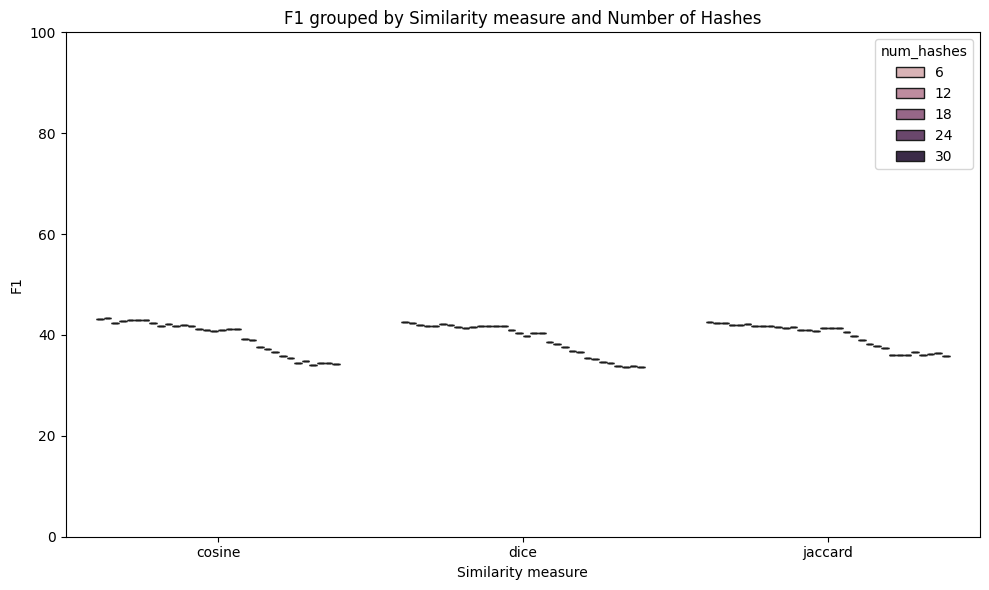

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [12]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1,Precision %,37.63
1,dice,1,Precision %,38.09
2,jaccard,1,Precision %,38.78
3,cosine,2,Precision %,37.46
4,dice,2,Precision %,37.39
...,...,...,...,...
283,dice,31,F1 %,33.87
284,jaccard,31,F1 %,36.33
285,cosine,32,F1 %,34.34
286,dice,32,F1 %,33.73


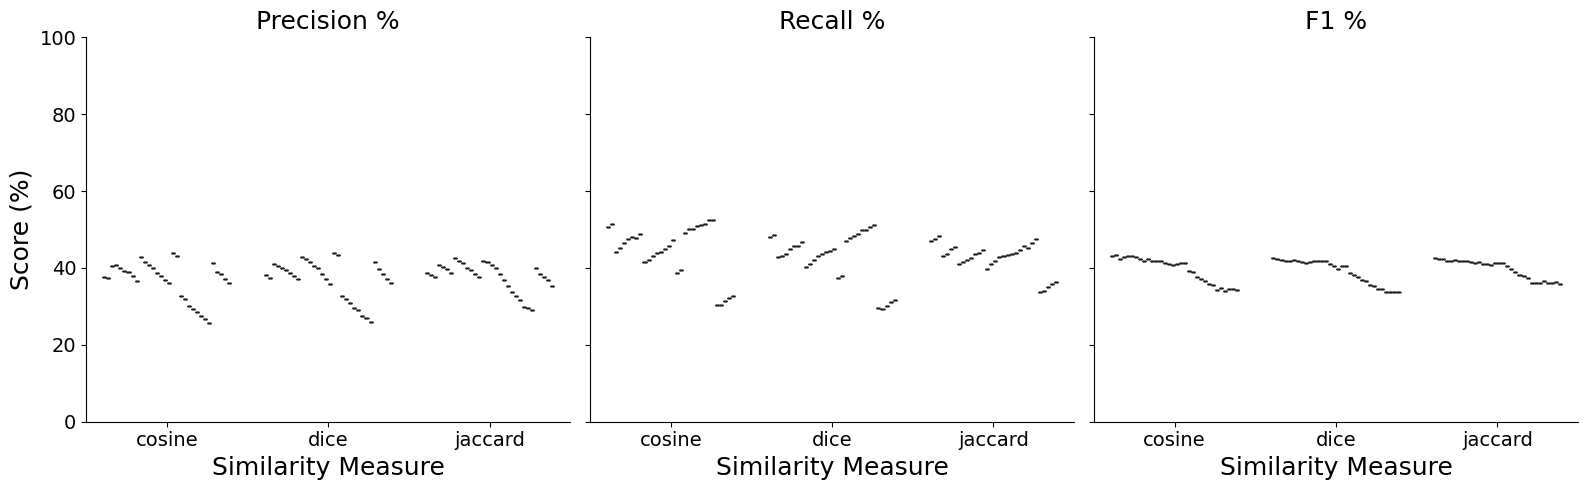

In [13]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

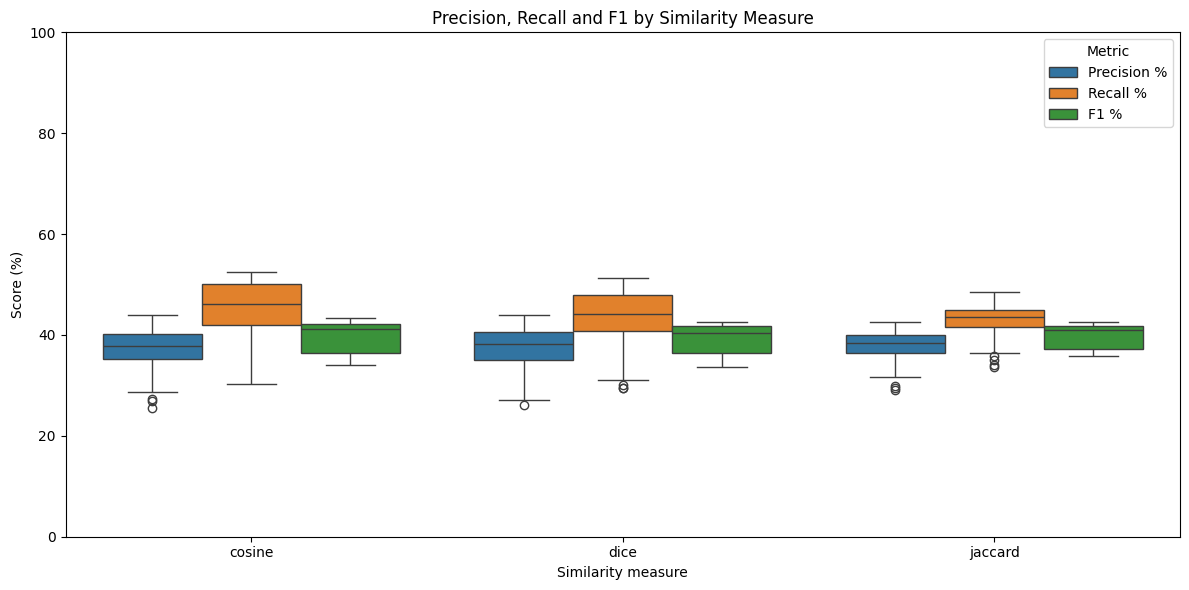

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()